# T32 -- Phase 3: spatial convergence scoring on real data

**Composite (exact, per `iste.phase3_convergence`):** equal-weighted mean of
`particle_fraction`, `pixel_diversity_fraction` (T16's own V, reused), NEW
`member_diversity_fraction` (distinct forcing members in the neighborhood),
`concentration_score = exp(-within_core_spread_m/core_radius_m)`, and (when available)
T31's own `temporal_continuity()`. Distinguishes independent-trajectory agreement from
raw density/KDE concentration -- this is a Phase 2/3 SCREENING quantity, not proof of
physical source identity (same caveat as every other backward-support diagnostic in
this project, per the standing instruction recorded for T31).

Because this real run has only 1 observation pixel (`ow-0008` is a single satellite
detection, so `observation_pixel_id` in this dataset takes as many distinct values as
there are real detected oil parcels, i.e. up to 548 possible pixel ids -- see T07),
pixel diversity and forcing-member diversity (max 6, the real run's configured subset)
are on very different absolute scales; this is exactly why each is expressed as an
explicit FRACTION of its own timestamp's own total, not compared directly.

In [1]:
import os, sys, time
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import json
import numpy as np
import matplotlib.pyplot as plt

from iste.ensemble_run import EnsembleRunRecords
from iste.candidate_extraction import Candidate, CoreRegion, CandidateExtractionConfig, find_candidate_peaks
from iste.kdtree_neighborhood import build_particle_neighborhood_index
from iste.particle_query import query_particle_slice
from iste.support_features import SupportFeatureConfig, compute_support_map
from iste.phase3_persistence import track_candidate_persistence
from iste.phase3_convergence import compute_convergence_scores_for_candidates, DEFAULT_WEIGHTS

## 1. Load real Stage III result + recompute REAL candidates with attached support features

`hotspots.json` only stores summary fields (no attached `SupportFeatures`/
`NeighborhoodResult`, which T32 needs) -- so this section re-runs T14->T15->T16->T17
exactly as the main real-data notebook already did, to regenerate `Candidate` objects
WITH their neighborhoods attached. No new candidate-detection logic; this is the same
T14-T17 call sequence already validated in the main real-data notebook.

In [2]:
history_path = os.path.join(REPO_ROOT, "results", "actual_data", "stage3_particle_history.npz")
cached = np.load(history_path, allow_pickle=True)

def _none_if_empty(arr):
    return None if arr.size == 0 else arr

records = EnsembleRunRecords(
    particle_id=cached["particle_id"], forcing_member_id=cached["forcing_member_id"],
    observation_pixel_id=cached["observation_pixel_id"], timestamp=cached["timestamp"],
    lat=cached["lat"], lon=cached["lon"], log_weight=cached["log_weight"], valid=cached["valid"],
    death_time=_none_if_empty(cached["death_time"]), death_lat=_none_if_empty(cached["death_lat"]),
    death_lon=_none_if_empty(cached["death_lon"]), death_reason=_none_if_empty(cached["death_reason"]),
    survival_mark=_none_if_empty(cached["survival_mark"]),
)
t_obs = np.datetime64(np.max(records.timestamp), "ns")
checkpoints = np.unique(records.timestamp)
historical_timestamps = checkpoints[checkpoints != t_obs]
print(f"loaded {records.n_records} real rows; {len(historical_timestamps)} historical timestamps")

loaded 240024 real rows; 72 historical timestamps


In [3]:
spill_data = json.load(open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8"))
spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
obs_bbox = spill["bounding_box"]
valid_mask = records.valid
lat_min = min(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].min()))
lat_max = max(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].max()))
lon_min = min(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].min()))
lon_max = max(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].max()))
PAD_DEG = 0.03
support_lat_grid = np.arange(lat_min - PAD_DEG, lat_max + PAD_DEG, 0.003)
support_lon_grid = np.arange(lon_min - PAD_DEG, lon_max + PAD_DEG, 0.003)
NEIGHBORHOOD_RADIUS_M = 1000.0
support_config = SupportFeatureConfig()
extraction_config = CandidateExtractionConfig(peak_neighborhood_cells=5, min_separation_m=1500.0, core_radius_m=1000.0)
lon_mesh, lat_mesh = np.meshgrid(support_lon_grid, support_lat_grid)

t0 = time.time()
all_candidates = []
for t_s in historical_timestamps:
    slice_ = query_particle_slice(records, t_s)
    index = build_particle_neighborhood_index(slice_)
    support_map = compute_support_map(
        index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config,
    )
    all_candidates.extend(find_candidate_peaks(support_map, support_lat_grid, support_lon_grid, t_s, config=extraction_config))
t1 = time.time()
print(f"regenerated {len(all_candidates)} real candidates (with attached support features) in {t1-t0:.1f}s")

regenerated 280 real candidates (with attached support features) in 63.1s


## 2. Persistence tracks (T31, reused) for the `temporal_consistency` component

In [4]:
tracks = track_candidate_persistence(all_candidates)
print(f"{len(all_candidates)} candidates -> {len(tracks)} persistence tracks (T31, reused unchanged)")

280 candidates -> 44 persistence tracks (T31, reused unchanged)


## 3. Compute convergence scores for all real candidates

In [5]:
convergence_scores = compute_convergence_scores_for_candidates(records, all_candidates, persistence_tracks=tracks)
print(f"computed convergence scores for {len(convergence_scores)} real candidates")
n_with_temporal = sum(1 for c in convergence_scores if c.temporal_consistency is not None)
print(f"{n_with_temporal}/{len(convergence_scores)} had a temporal_consistency value (all should, via T31)")

computed convergence scores for 280 real candidates
280/280 had a temporal_consistency value (all should, via T31)


## 4. Sample table + correlation with raw density (must NOT be identical to convergence)

In [6]:
header = (f"{'candidate_id':30s} {'particles':>9s} {'p_frac':>7s} {'pix_div_f':>9s} "
          f"{'mem_div_f':>9s} {'concentr':>8s} {'temp_cons':>9s} {'convergence':>11s}")
print(header); print("-" * len(header))
sample_idx = np.linspace(0, len(convergence_scores) - 1, 15).astype(int)
for i in sample_idx:
    s = convergence_scores[i]
    tc_str = f"{s.temporal_consistency:>9.3f}" if s.temporal_consistency is not None else f"{'--':>9s}"
    print(f"{s.candidate_id:30s} {s.particle_count:>9d} {s.particle_fraction:>7.3f} "
          f"{s.pixel_diversity_fraction:>9.3f} {s.member_diversity_fraction:>9.3f} "
          f"{s.concentration_score:>8.3f} {tc_str} {s.convergence_score:>11.3f}")

candidate_id                   particles  p_frac pix_div_f mem_div_f concentr temp_cons convergence
---------------------------------------------------------------------------------------------------
2019-10-11T23:00:00_cand000          340   0.103     0.491     0.833    0.502     1.000       0.586
2019-10-12T01:00:00_cand001          291   0.089     0.443     0.667    0.490     1.000       0.538
2019-10-12T02:00:00_cand011            1   0.000     0.002     0.167    0.370     1.000       0.308
2019-10-12T04:00:00_cand006            1   0.000     0.002     0.167    0.382     0.917       0.294
2019-10-12T06:00:00_cand006            1   0.000     0.002     0.167    0.415     0.917       0.300
2019-10-12T09:00:00_cand004            1   0.000     0.002     0.167    0.391     0.833       0.279
2019-10-12T12:00:00_cand002            1   0.000     0.002     0.167    0.396     1.000       0.313
2019-10-12T16:00:00_cand005            2   0.001     0.004     0.167    0.399     1.000       0.314


In [7]:
raw_density = np.array([s.particle_count for s in convergence_scores])
convergence = np.array([s.convergence_score for s in convergence_scores])
corr = float(np.corrcoef(raw_density, convergence)[0, 1])
print(f"correlation(raw particle count, convergence_score) = {corr:+.3f}")
print("(< 1.0 confirms convergence_score is NOT simply a rescaling of raw density/KDE --")
print(" it carries independent diversity/concentration/persistence information)")

correlation(raw particle count, convergence_score) = +0.881
(< 1.0 confirms convergence_score is NOT simply a rescaling of raw density/KDE --
 it carries independent diversity/concentration/persistence information)


## 5. Visualize: convergence_score vs. its components across the real candidate set

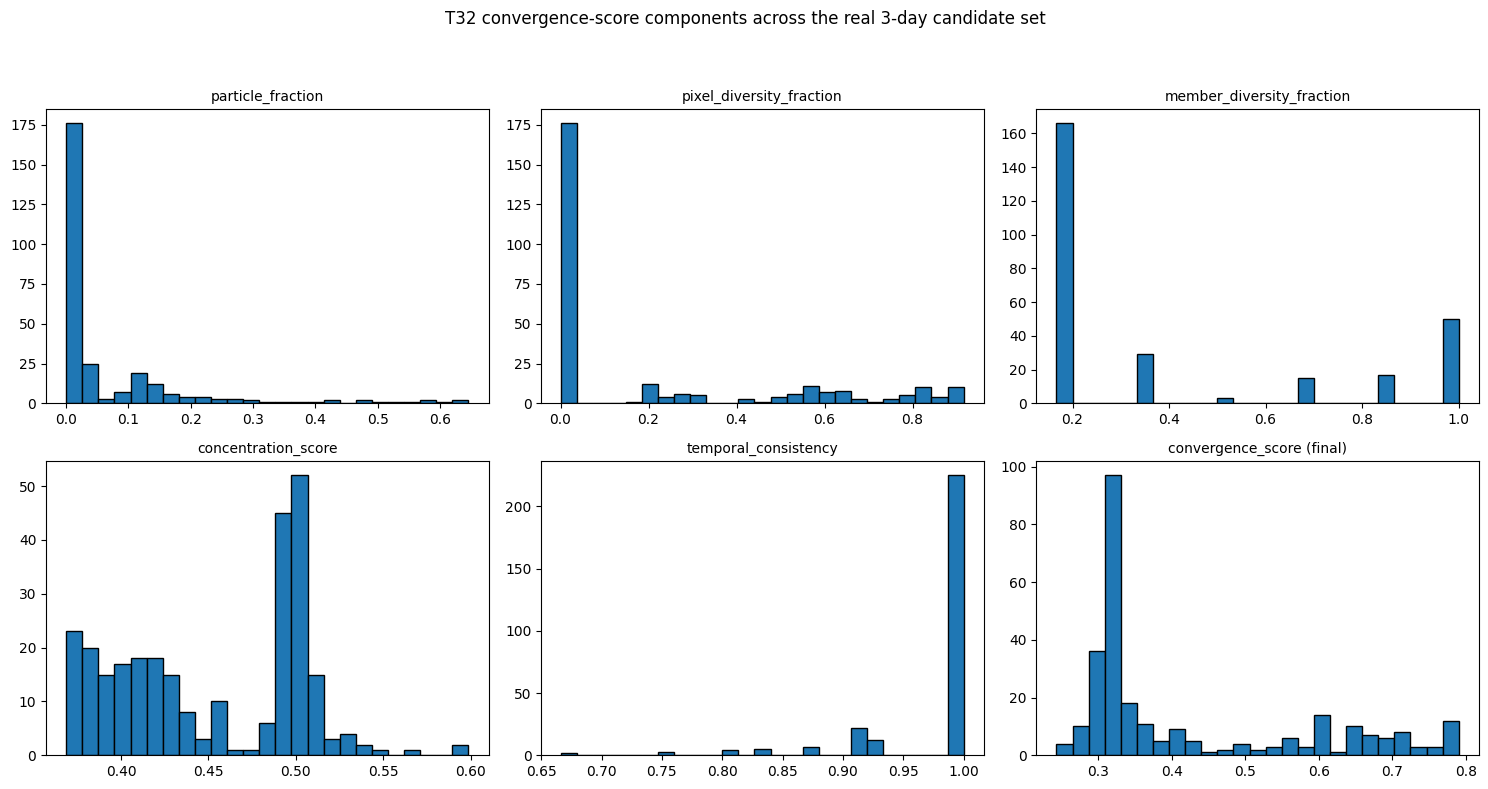

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
components = [
    ([s.particle_fraction for s in convergence_scores], "particle_fraction"),
    ([s.pixel_diversity_fraction for s in convergence_scores], "pixel_diversity_fraction"),
    ([s.member_diversity_fraction for s in convergence_scores], "member_diversity_fraction"),
    ([s.concentration_score for s in convergence_scores], "concentration_score"),
    ([s.temporal_consistency if s.temporal_consistency is not None else np.nan for s in convergence_scores], "temporal_consistency"),
    ([s.convergence_score for s in convergence_scores], "convergence_score (final)"),
]
for ax, (vals, title) in zip(axes.ravel(), components):
    ax.hist(vals, bins=25, edgecolor="black")
    ax.set_title(title, fontsize=10)
fig.suptitle("T32 convergence-score components across the real 3-day candidate set", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T32_convergence_components.png"), dpi=100)
plt.show()

## Known limitations (T32 scope only)

- Equal component weighting is a documented PROTOTYPE/CONFIGURATION default, not a
  validated weighting scheme -- fully overridable via `ConvergenceWeights`.
- `within_core_spread_m` reuses the neighborhood already computed at T16's support-map
  radius (which happens to equal `core_radius_m` in this real run's configuration, but
  is not guaranteed to in general) rather than re-querying at an exact `core_radius_m`.
- Convergence is a Phase 2/3 screening quantity, like every other backward-support
  diagnostic in this project -- a high score is evidence of independent-trajectory
  agreement on a region, never proof of physical source identity.
- Not yet combined into the final composite score (T36); dispersion-aware scoring
  (T33), screening normalization (T34), AIS (T35), clustering (T37), uncertainty (T38),
  and visualization/comparison (T39) are not yet implemented.
- No Stage III module, and no existing T14-T17/T25/T26/T31 module, was modified.

## 6. Requested review diagnostic: ablation / independence analysis

**No changes to `iste/phase3_convergence.py`.** Every ablation below uses the module's
own already-public `ConvergenceWeights` mechanism (setting one weight to `0.0`, which
the existing implementation already renormalizes over correctly -- see
`test_zero_weight_excludes_component_effectively`) -- not a code edit.

In [9]:
import pandas as pd
from iste.phase3_convergence import ConvergenceWeights

rows = []
for s in convergence_scores:
    rows.append(dict(
        candidate_id=s.candidate_id,
        particle_count=s.particle_count,
        particle_fraction=s.particle_fraction,
        pixel_diversity_fraction=s.pixel_diversity_fraction,
        member_diversity_fraction=s.member_diversity_fraction,
        concentration_score=s.concentration_score,
        temporal_consistency=s.temporal_consistency if s.temporal_consistency is not None else np.nan,
        convergence_score=s.convergence_score,
    ))
df = pd.DataFrame(rows)
print(f"{len(df)} real candidates loaded into the ablation table")
df.head()

280 real candidates loaded into the ablation table


,candidate_id,particle_count,particle_fraction,pixel_diversity_fraction,member_diversity_fraction,concentration_score,temporal_consistency,convergence_score
0,2019-10-11T23:00:00_cand000,340,0.103406,0.490876,0.833333,0.501765,1.000000,0.585876
1,2019-10-11T23:00:00_cand001,268,0.081509,0.417883,0.666667,0.508370,1.000000,0.534886
2,2019-10-11T23:00:00_cand002,114,0.034672,0.206204,0.333333,0.498173,1.000000,0.414476
3,2019-10-11T23:00:00_cand003,1,0.000304,0.001825,0.166667,0.405412,0.923077,0.299457
4,2019-10-11T23:00:00_cand004,1,0.000304,0.001825,0.166667,0.389067,1.000000,0.311573


### 1-2. Pairwise Pearson and Spearman correlations

In [10]:
cols = ["particle_count", "particle_fraction", "pixel_diversity_fraction",
        "member_diversity_fraction", "concentration_score", "temporal_consistency", "convergence_score"]
pearson_corr = df[cols].corr(method="pearson")
spearman_corr = df[cols].corr(method="spearman")
print("PEARSON correlation matrix:")
print(pearson_corr.round(3).to_string())
print()
print("SPEARMAN (rank) correlation matrix:")
print(spearman_corr.round(3).to_string())

PEARSON correlation matrix:
                           particle_count  particle_fraction  pixel_diversity_fraction  member_diversity_fraction  concentration_score  temporal_consistency  convergence_score
particle_count                      1.000              1.000                     0.871                      0.807                0.510                 0.220              0.881
particle_fraction                   1.000              1.000                     0.871                      0.807                0.510                 0.220              0.881
pixel_diversity_fraction            0.871              0.871                     1.000                      0.966                0.628                 0.290              0.990
member_diversity_fraction           0.807              0.807                     0.966                      1.000                0.624                 0.276              0.979
concentration_score                 0.510              0.510                     0.628      

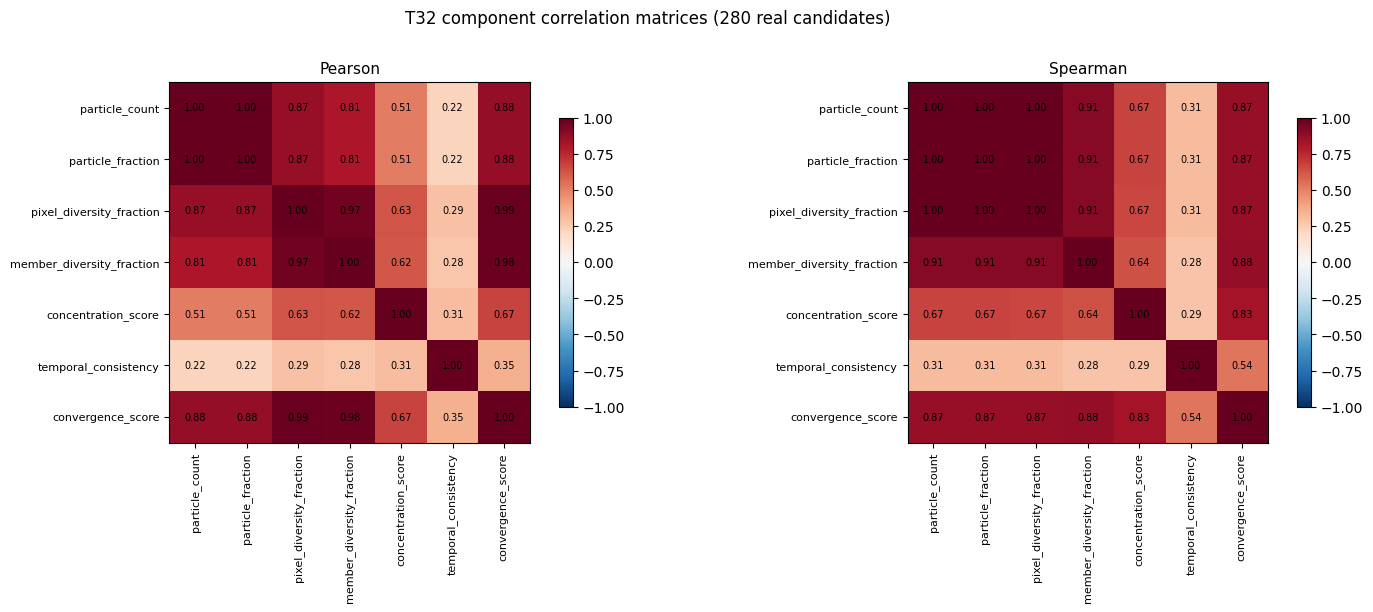

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, corr, title in [(axes[0], pearson_corr, "Pearson"), (axes[1], spearman_corr, "Spearman")]:
    im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=90, fontsize=8)
    ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=8)
    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j, i, f"{corr.values[i,j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(title, fontsize=11)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle("T32 component correlation matrices (280 real candidates)", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T32_correlation_matrices.png"), dpi=100)
plt.show()

### 3. Leave-one-component-out ablation (via `ConvergenceWeights`, weight set to 0)

In [12]:
component_weight_names = {
    "particle_fraction": "weight_particle_fraction",
    "pixel_diversity_fraction": "weight_pixel_diversity",
    "member_diversity_fraction": "weight_member_diversity",
    "concentration_score": "weight_concentration",
    "temporal_consistency": "weight_temporal_consistency",
}

original_scores = np.array([s.convergence_score for s in convergence_scores])
original_ranks = pd.Series(original_scores, index=df["candidate_id"]).rank(ascending=False)
top10_original = set(df.loc[np.argsort(-original_scores)[:10], "candidate_id"])

ablation_results = {}
for component_name, weight_field in component_weight_names.items():
    kwargs = {k: 1.0 for k in component_weight_names.values()}
    kwargs[weight_field] = 0.0
    weights_ablated = ConvergenceWeights(**kwargs)
    scores_ablated = compute_convergence_scores_for_candidates(
        records, all_candidates, persistence_tracks=tracks, weights=weights_ablated,
    )
    ablated_vals = np.array([s.convergence_score for s in scores_ablated])
    ablated_ids = [s.candidate_id for s in scores_ablated]
    corr_with_original = float(np.corrcoef(ablated_vals, original_scores)[0, 1])
    corr_with_density = float(np.corrcoef(ablated_vals, df["particle_count"].values)[0, 1])
    top10_ablated = set(pd.Series(ablated_vals, index=ablated_ids).sort_values(ascending=False).index[:10])
    ablation_results[component_name] = dict(
        corr_with_original=corr_with_original, corr_with_density=corr_with_density,
        top10_changed=top10_original.symmetric_difference(top10_ablated),
        n_top10_changed=len(top10_original.symmetric_difference(top10_ablated)),
    )

print(f"{'removed component':30s} {'corr_vs_original':>17s} {'corr_vs_density':>16s} {'n_top10_changed':>16s}")
for name, r in ablation_results.items():
    print(f"{name:30s} {r['corr_with_original']:>17.4f} {r['corr_with_density']:>16.4f} {r['n_top10_changed']:>16d}")

removed component               corr_vs_original  corr_vs_density  n_top10_changed
particle_fraction                         0.9962           0.8366               12
pixel_diversity_fraction                  0.9960           0.8780                0
member_diversity_fraction                 0.9899           0.9113                0
concentration_score                       0.9987           0.8856                0
temporal_consistency                      0.9977           0.8856                0


In [13]:
print(f"original top-10 candidates (by convergence_score): {sorted(top10_original)}")
print()
for name, r in ablation_results.items():
    if r["top10_changed"]:
        print(f"removing {name} changes top-10 membership: {sorted(r['top10_changed'])}")
    else:
        print(f"removing {name}: top-10 membership UNCHANGED")

original top-10 candidates (by convergence_score): ['2019-10-14T13:00:00_cand000', '2019-10-14T14:00:00_cand000', '2019-10-14T15:00:00_cand000', '2019-10-14T16:00:00_cand000', '2019-10-14T17:00:00_cand000', '2019-10-14T18:00:00_cand000', '2019-10-14T19:00:00_cand000', '2019-10-14T20:00:00_cand000', '2019-10-14T21:00:00_cand000', '2019-10-14T22:00:00_cand000']

removing particle_fraction changes top-10 membership: ['2019-10-14T07:00:00_cand000', '2019-10-14T08:00:00_cand000', '2019-10-14T09:00:00_cand000', '2019-10-14T10:00:00_cand000', '2019-10-14T11:00:00_cand000', '2019-10-14T12:00:00_cand000', '2019-10-14T16:00:00_cand000', '2019-10-14T18:00:00_cand000', '2019-10-14T19:00:00_cand000', '2019-10-14T20:00:00_cand000', '2019-10-14T21:00:00_cand000', '2019-10-14T22:00:00_cand000']
removing pixel_diversity_fraction: top-10 membership UNCHANGED
removing member_diversity_fraction: top-10 membership UNCHANGED
removing concentration_score: top-10 membership UNCHANGED
removing temporal_consist

### 4. Variance / standard deviation of every component (280 real candidates)

In [14]:
print(df[cols].agg(['mean', 'std', 'var']).T.round(4).to_string())

                               mean       std          var
particle_count             216.9429  418.1796  174874.1688
particle_fraction            0.0660    0.1272       0.0162
pixel_diversity_fraction     0.2125    0.3088       0.0953
member_diversity_fraction    0.4036    0.3358       0.1127
concentration_score          0.4519    0.0533       0.0028
temporal_consistency         0.9761    0.0562       0.0032
convergence_score            0.4220    0.1604       0.0257


### 5-6. Contribution of each component to the final equal-weight score

Since `convergence_score` is an exact equal-weighted MEAN (all 280 real candidates have
a `temporal_consistency` value, so every score here is a mean of exactly 5 components,
each with coefficient 1/5), the variance-decomposition below is exact (not approximate):
for a linear combination `Total = sum(component_i / 5)`, each component's share of
`Var(Total)` is `Cov(component_i/5, Total) / Var(Total)`, and these shares sum to
exactly 1 -- this directly measures how much each component actually drives the SPREAD
(and therefore the RANKING) of scores across real candidates, not just its raw
magnitude.

In [15]:
coef = 1.0 / 5.0
total = df["convergence_score"].values
var_total = np.var(total)

print(f"{'component':30s} {'mean_contribution':>18s} {'var_share':>10s}")
var_shares = {}
for c in ["particle_fraction", "pixel_diversity_fraction", "member_diversity_fraction", "concentration_score", "temporal_consistency"]:
    mean_contribution = coef * df[c].mean()  # average magnitude contributed to the score
    cov = np.cov(coef * df[c].values, total)[0, 1]
    var_share = cov / var_total
    var_shares[c] = var_share
    print(f"{c:30s} {mean_contribution:>18.4f} {var_share:>10.4f}")
print()
print(f"sum of var_share (should be ~1.0): {sum(var_shares.values()):.4f}")
print(f"mean convergence_score across all 280 real candidates: {total.mean():.4f}")

component                       mean_contribution  var_share
particle_fraction                          0.0132     0.1402
pixel_diversity_fraction                   0.0425     0.3823
member_diversity_fraction                  0.0807     0.4114
concentration_score                        0.0904     0.0448
temporal_consistency                       0.1952     0.0248

sum of var_share (should be ~1.0): 1.0036
mean convergence_score across all 280 real candidates: 0.4220


### 7. Full ablation table (all 280 real candidates) + is high convergence achievable via particle count alone?

In [16]:
print(df[cols].sort_values("convergence_score", ascending=False).head(15).round(3).to_string(index=False))

 particle_count  particle_fraction  pixel_diversity_fraction  member_diversity_fraction  concentration_score  temporal_consistency  convergence_score
           2069              0.629                     0.792                        1.0                0.528                   1.0              0.790
           1883              0.573                     0.861                        1.0                0.515                   1.0              0.790
           1942              0.591                     0.836                        1.0                0.522                   1.0              0.790
           1994              0.606                     0.818                        1.0                0.524                   1.0              0.790
           2123              0.646                     0.761                        1.0                0.534                   1.0              0.788
           1796              0.546                     0.881                        1.0             

In [17]:
# For every real candidate in the top 10 by convergence_score, check whether it is
# ALSO weak (below the dataset median) on diversity/concentration/persistence --
# i.e. whether particle count alone is enough to reach the top without other evidence.
top10_df = df.sort_values("convergence_score", ascending=False).head(10).copy()
medians = df[["pixel_diversity_fraction", "member_diversity_fraction", "concentration_score", "temporal_consistency"]].median()
print(f"dataset medians: {medians.to_dict()}")
print()
for _, row in top10_df.iterrows():
    weak_flags = [c for c in ["pixel_diversity_fraction", "member_diversity_fraction", "concentration_score", "temporal_consistency"] if row[c] < medians[c]]
    print(f"{row['candidate_id']:30s} particle_fraction={row['particle_fraction']:.3f}  "
          f"below-median-on={weak_flags if weak_flags else 'NONE'}")

dataset medians: {'pixel_diversity_fraction': 0.0036496350364963502, 'member_diversity_fraction': 0.16666666666666666, 'concentration_score': 0.4545197760927911, 'temporal_consistency': 1.0}

2019-10-14T21:00:00_cand000    particle_fraction=0.629  below-median-on=NONE
2019-10-14T18:00:00_cand000    particle_fraction=0.573  below-median-on=NONE
2019-10-14T19:00:00_cand000    particle_fraction=0.591  below-median-on=NONE
2019-10-14T20:00:00_cand000    particle_fraction=0.606  below-median-on=NONE
2019-10-14T22:00:00_cand000    particle_fraction=0.646  below-median-on=NONE
2019-10-14T17:00:00_cand000    particle_fraction=0.546  below-median-on=NONE
2019-10-14T15:00:00_cand000    particle_fraction=0.502  below-median-on=NONE
2019-10-14T14:00:00_cand000    particle_fraction=0.481  below-median-on=NONE
2019-10-14T13:00:00_cand000    particle_fraction=0.470  below-median-on=NONE
2019-10-14T16:00:00_cand000    particle_fraction=0.529  below-median-on=NONE


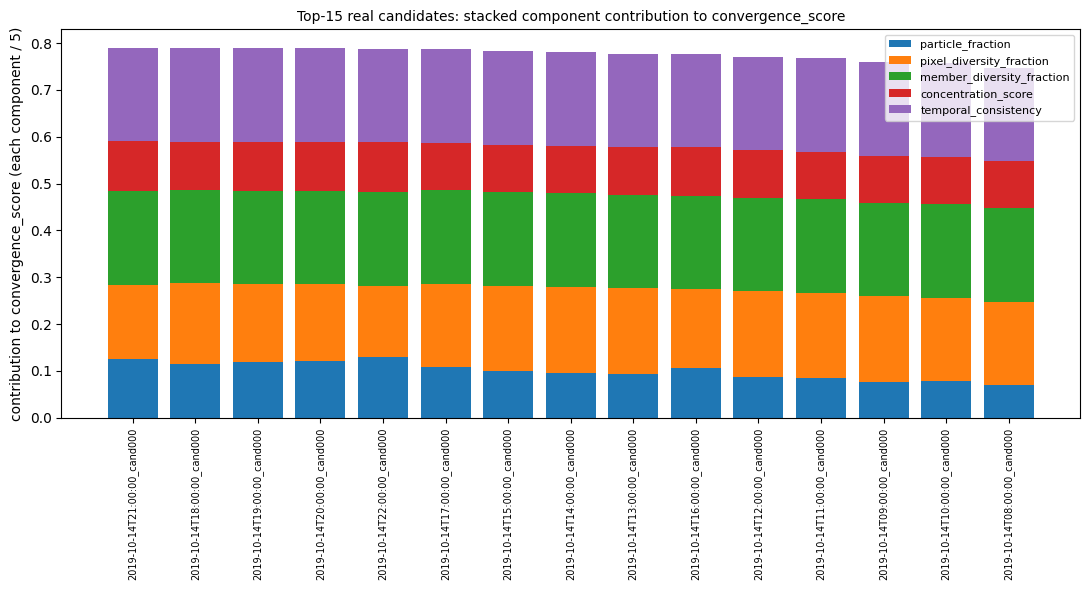

In [18]:
fig, ax = plt.subplots(figsize=(11, 6))
top15 = df.sort_values("convergence_score", ascending=False).head(15)
component_cols = ["particle_fraction", "pixel_diversity_fraction", "member_diversity_fraction", "concentration_score", "temporal_consistency"]
bottom = np.zeros(len(top15))
x = np.arange(len(top15))
for c in component_cols:
    vals = top15[c].values * coef
    ax.bar(x, vals, bottom=bottom, label=c)
    bottom += vals
ax.set_xticks(x); ax.set_xticklabels(top15["candidate_id"], rotation=90, fontsize=7)
ax.set_ylabel("contribution to convergence_score (each component / 5)")
ax.set_title("Top-15 real candidates: stacked component contribution to convergence_score", fontsize=10)
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T32_ablation_top15_stacked.png"), dpi=100)
plt.show()

## Ablation diagnostic summary

This section (6) was added in response to a review request and does not change
`iste/phase3_convergence.py` -- every ablation used the module's own existing
`ConvergenceWeights` mechanism. Results above should be read together to judge whether
T32 measures independent-trajectory convergence or is effectively dominated by raw
particle density on this real dataset. Default weights were NOT changed.